<a href="https://colab.research.google.com/github/aldwlsl/26-2-DIP-202302290/blob/main/HW02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **HW02 - Image Restoration**

---



In [42]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

In [43]:
import nibabel as nib
from google.colab import drive
drive.mount('/content/drive')
import os
imgpath = '/content/drive/MyDrive/DIP4E/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [44]:
print(os.listdir(imgpath))

['test-pattern-gaussian-noise.tif', 'Fig81c.tif', 'WashingtonDC-Band4-NearInfrared-564.tif', 'glass-caster-RGB.tif', 'numbers.tif', 'cktboard-controller.tif', 'four-squares.tif', 'testpattern8192.tif', 'turbineblad-with-blk-dot.tif', 'letterA-distorted.tif', 'GT.tif', 'Fig81b.tif', 'galaxy-pair.tif', 'polymercell.tif', 'washingtonDC-Band6-ThermalInfrared-512.tif', 'edge-roof.tif', 'angiography-mask-image.tif', 'lenna-RGB.tif', 'strip-uniform-noise.tif', 'RGB-color-cube.tif', 'painting.tif', 'wingding-circle-target.tif', 'book-cover-gaussian.tif', 'OpticalMicroscope-superconductor-smooth-texture.tif', 'americas-at-night4.tif', 'calculator-binary.tif', 'wingding-star-3pt.tif', 'matches-aligned.tif', 'hurricane-katrina-eye.tif', 'shepp-logan-phantom.tif', 'cygnusloop.tif', 'Fig81a.tif', 'wingding-circle-solid.tif', 'bonescan-back.tif', 'dowels.tif', 'phobos.tif', 'wingding-square-solid.tif', 'WashingtonDC-RGBfrom-Bands-4-2-1.tif', 'blurry-moon.tif', 'lenna-gray.tif', 'text-sineshade.tif',

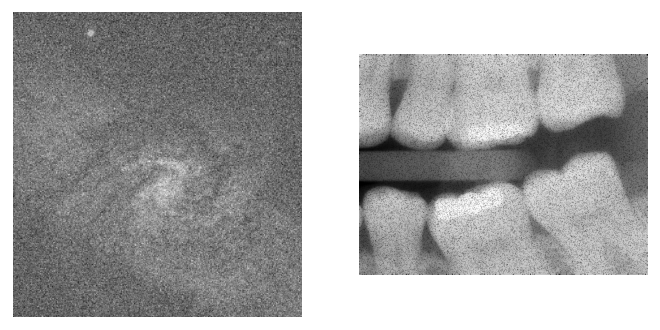

In [53]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

f1 (galaxy) : shape=(598, 566), min=0.0, max=255.0, 최솟값 픽셀 비율=0.00%
f2 (dental) : shape=(680, 888), min=0.0, max=255.0, 최솟값 픽셀 비율=10.01%


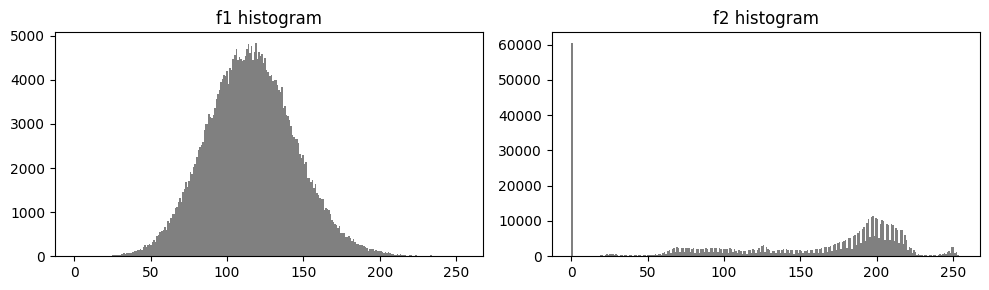

In [54]:
def to_gray_float(img):
    img = img.astype(np.float64)
    if img.ndim == 3:
        img = img[..., 0]
    return img

g1 = to_gray_float(f1)
g2 = to_gray_float(f2)

for name, g in [('f1 (galaxy)', g1), ('f2 (dental)', g2)]:
    print('{} : shape={}, min={:.1f}, max={:.1f}, 최솟값 픽셀 비율={:.2f}%'.format(
        name, g.shape, g.min(), g.max(), (g == g.min()).mean()*100))

plt.figure(dpi=100, figsize=(10,3))
plt.subplot(121); plt.hist(g1.ravel(), bins=256, color='gray'); plt.title('f1 histogram')
plt.subplot(122); plt.hist(g2.ravel(), bins=256, color='gray'); plt.title('f2 histogram')
plt.tight_layout(); plt.show()

In [55]:
def get_windows(img, m=3, n=3):
    pm, pn = m//2, n//2
    padded = np.pad(img, ((pm, pm), (pn, pn)), mode='reflect')
    return sliding_window_view(padded, (m, n))

# Arithmetic Mean Filter

In [56]:
def arithmetic_mean_filter(img, m=3, n=3):
    return get_windows(img, m, n).mean(axis=(-2, -1))

# Median Filter

In [57]:
def median_filter(img, m=3, n=3):
    return np.median(get_windows(img, m, n), axis=(-2, -1))

# Adaptive Local Noise Reduction Filter

In [59]:
def adaptive_local_noise_reduction(img, m=7, n=7, noise_var=None):
    W = get_windows(img, m, n)
    mL   = W.mean(axis=(-2, -1))
    varL = W.var(axis=(-2, -1))
    if noise_var is None:
        noise_var = np.median(varL)
    ratio = noise_var / np.maximum(varL, 1e-12)
    ratio = np.minimum(ratio, 1.0)
    return img - ratio * (img - mL)

# f1(galaxy) 복원 /// 세 필터 비교

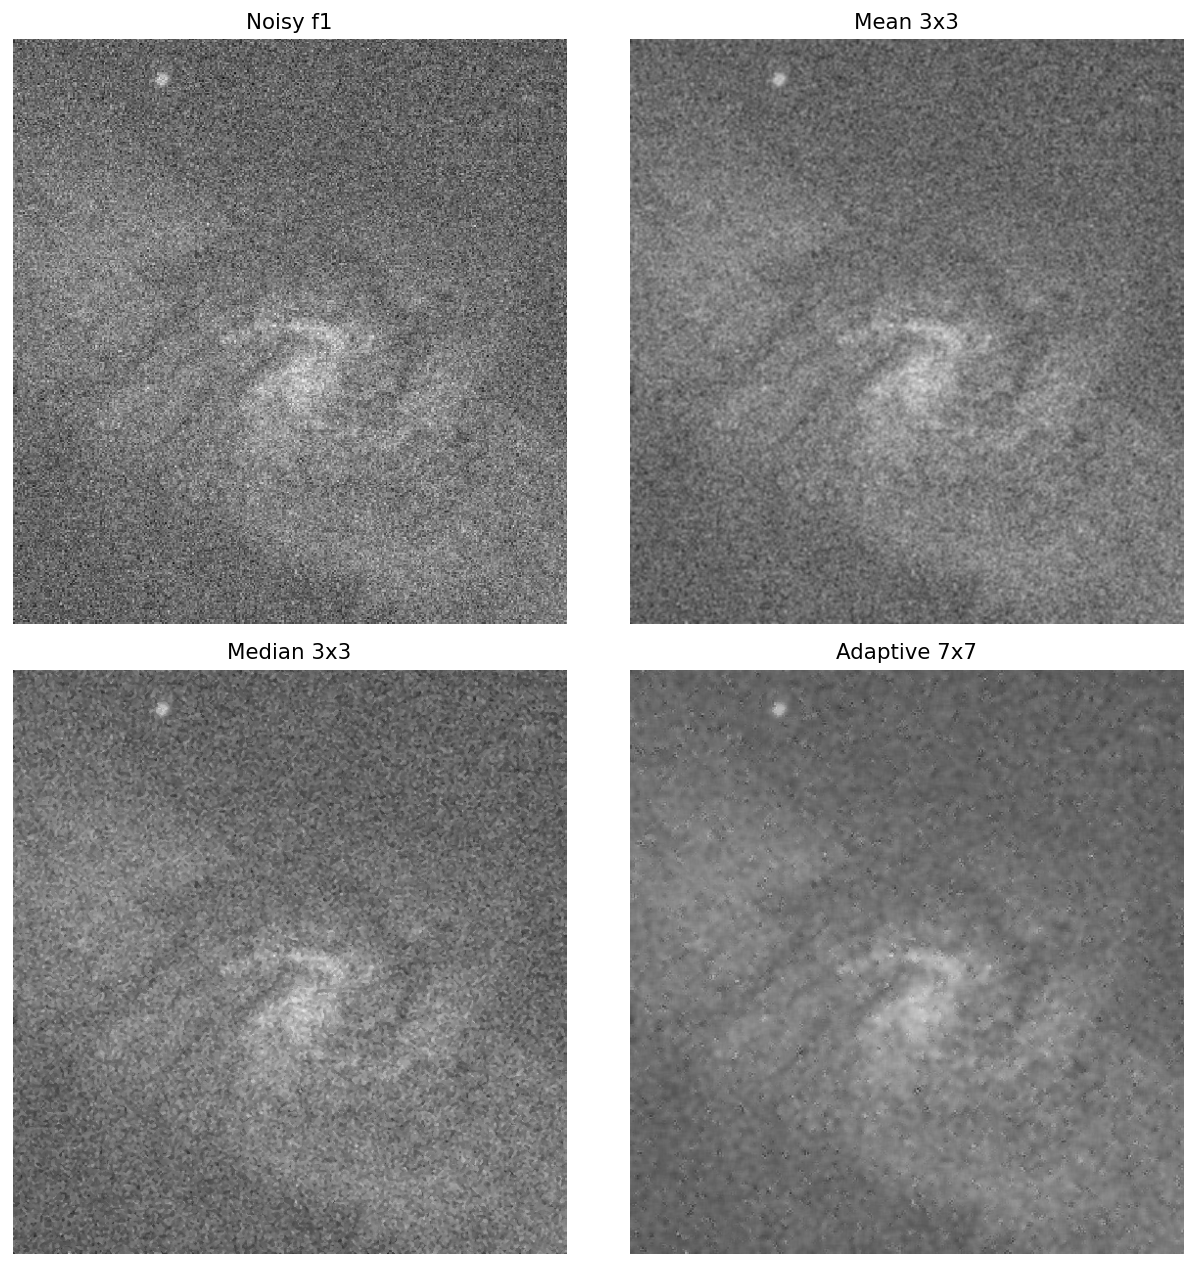

In [60]:
f1_mean = arithmetic_mean_filter(g1, 3, 3)
f1_med  = median_filter(g1, 3, 3)
f1_ad   = adaptive_local_noise_reduction(g1, 7, 7)

res1 = [(g1,'Noisy f1'), (f1_mean,'Mean 3x3'), (f1_med,'Median 3x3'), (f1_ad,'Adaptive 7x7')]
plt.figure(dpi=128, figsize=(10,10))
for i, (im, t) in enumerate(res1):
    plt.subplot(2,2,i+1); plt.imshow(im, cmap='gray', vmin=g1.min(), vmax=g1.max())
    plt.title(t); plt.axis('off')
plt.tight_layout(); plt.show()

# f2 (dental X-ray) 복원 /// 세 필터 비교

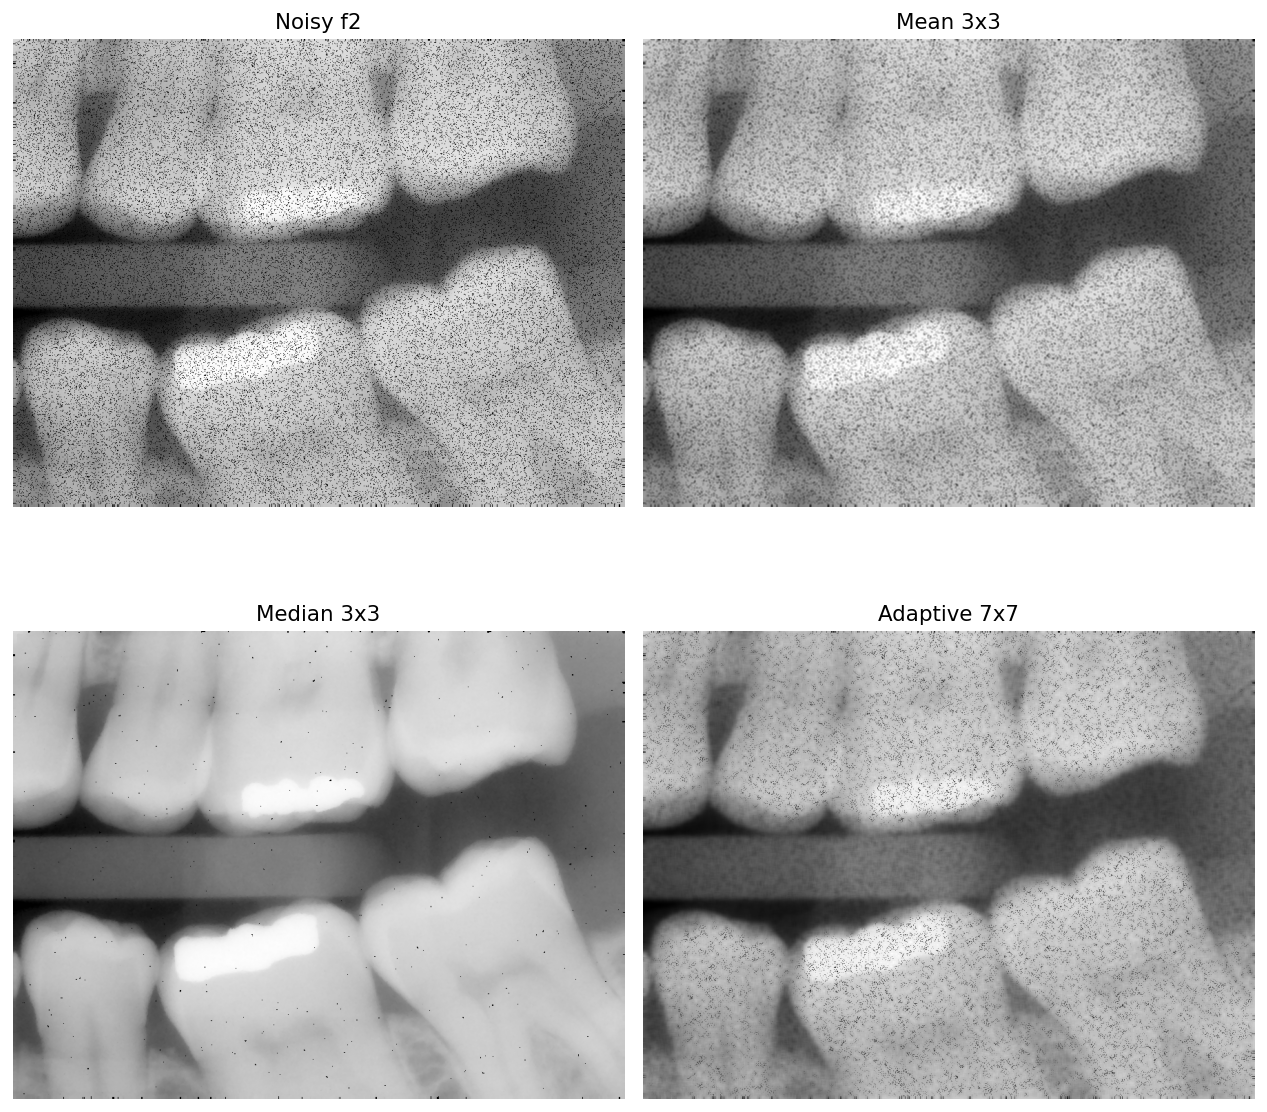

In [61]:
f2_mean = arithmetic_mean_filter(g2, 3, 3)
f2_med  = median_filter(g2, 3, 3)
f2_ad   = adaptive_local_noise_reduction(g2, 7, 7)

res2 = [(g2,'Noisy f2'), (f2_mean,'Mean 3x3'), (f2_med,'Median 3x3'), (f2_ad,'Adaptive 7x7')]
plt.figure(dpi=128, figsize=(10,10))
for i, (im, t) in enumerate(res2):
    plt.subplot(2,2,i+1); plt.imshow(im, cmap='gray', vmin=g2.min(), vmax=g2.max())
    plt.title(t); plt.axis('off')
plt.tight_layout(); plt.show()

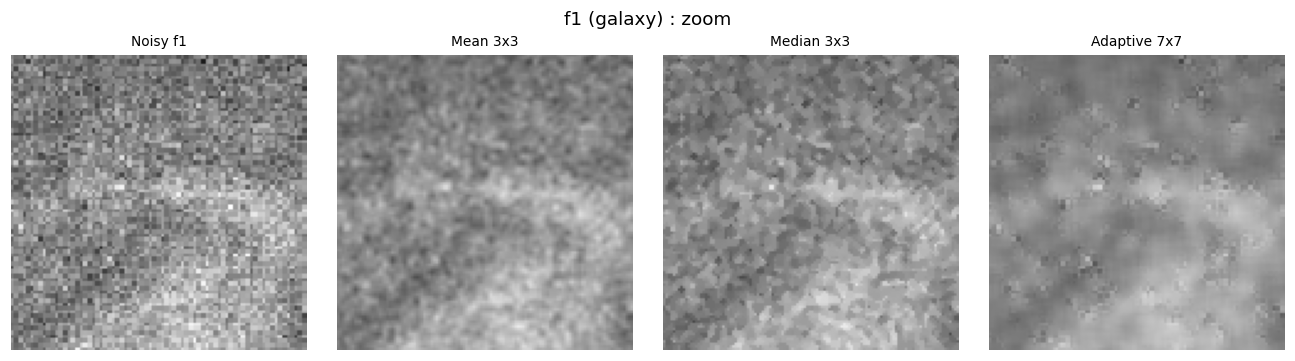

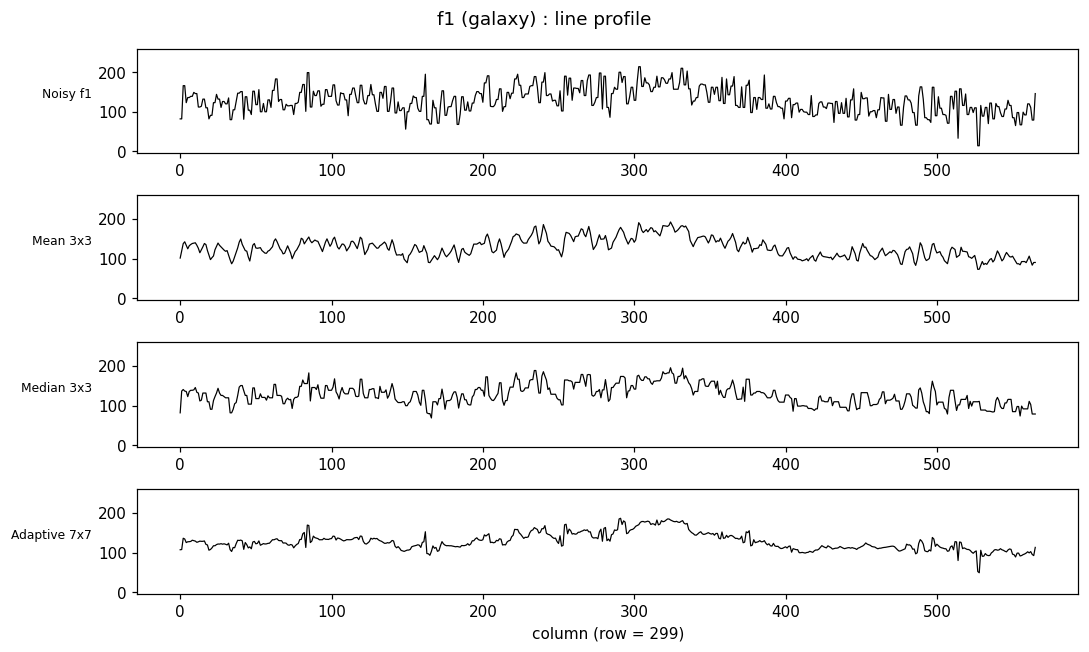

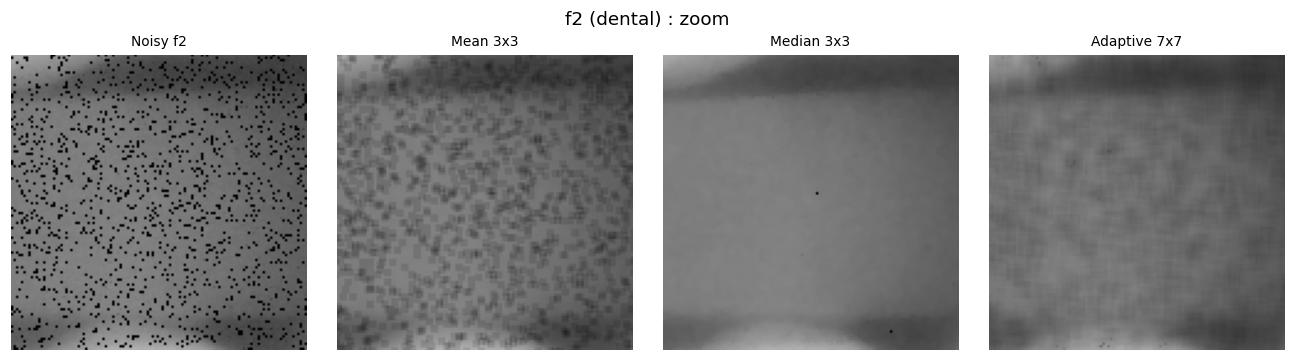

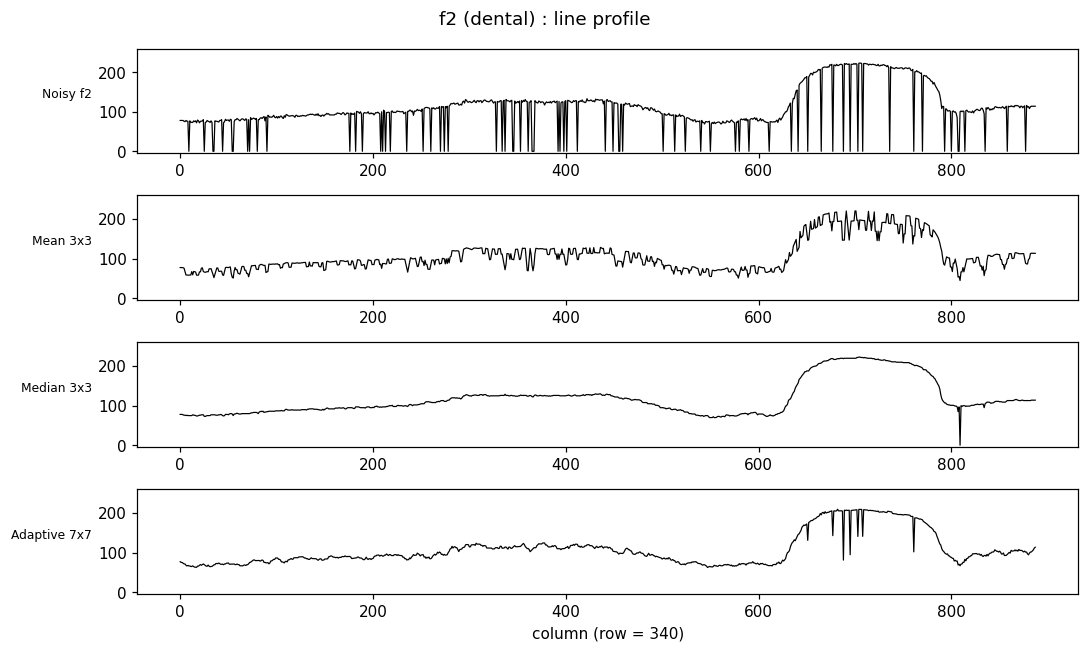

In [62]:
def zoom_and_profile(results, title):
    g = results[0][0]
    H, W = g.shape
    r0, c0, s = max(H//2-60,0), max(W//2-60,0), 120
    plt.figure(dpi=110, figsize=(12,3.3))
    for i, (im, t) in enumerate(results):
        plt.subplot(1,4,i+1)
        plt.imshow(im[r0:r0+s, c0:c0+s], cmap='gray', vmin=g.min(), vmax=g.max())
        plt.title(t, fontsize=9); plt.axis('off')
    plt.suptitle(title + ' : zoom'); plt.tight_layout(); plt.show()

    row = H//2
    plt.figure(dpi=110, figsize=(10,6))
    for i, (im, t) in enumerate(results):
        plt.subplot(4,1,i+1); plt.plot(im[row], lw=0.8, color='k')
        plt.ylim(g.min()-5, g.max()+5); plt.ylabel(t, fontsize=8, rotation=0, ha='right')
    plt.xlabel('column (row = {})'.format(row))
    plt.suptitle(title + ' : line profile'); plt.tight_layout(); plt.show()

zoom_and_profile(res1, 'f1 (galaxy)')
zoom_and_profile(res2, 'f2 (dental)')

# 복원된 f1,f2 시각화

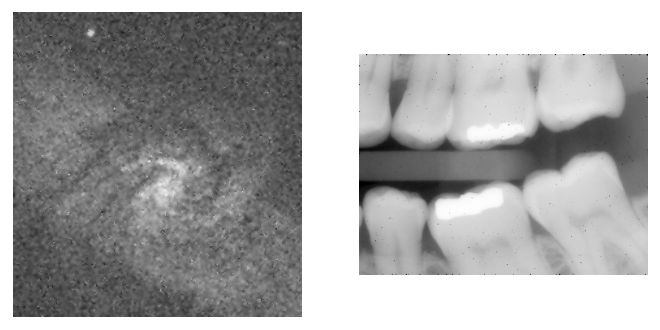

In [63]:
# f1_r: denoised f1
# f2_r: denoised f2
f1_r = f1_ad
f2_r = f2_med

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

In [66]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')